# Label smoothing : la régularisation sous-cotée

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/MonShotData/blob/main/Machine%20Learning/Label-Smoothing.ipynb)

📖 **Le shot complet** : [Label smoothing : la technique simple pour mieux généraliser](https://www.monshotdata.com/p/label-smoothing-regularisation)

---

Quand tu entraînes un classifieur, la cible est « 100 % pour la bonne classe, 0 % pour les autres ». Le modèle apprend donc à être **ultra-confiant**, même quand il se trompe. Le **label smoothing** adoucit cette cible, par exemple 80 % pour la bonne classe, et le reste réparti sur les autres. Une ligne dans PyTorch, et des probabilités de sortie moins extrêmes.

**À la fin de ce notebook, tu sauras :**

- ce que fait le label smoothing sur les cibles, et ce que calcule exactement `label_smoothing` dans PyTorch ;
- entraîner le même réseau avec et sans label smoothing, sur Fashion MNIST, et comparer précision et perte de test ;
- mesurer l'effet réel : les probabilités de sortie et la **confiance moyenne** du modèle comparée à sa précision, pour ε = 0,1 et ε = 0,2.

### Avant de lancer

- **Installation** : PyTorch et torchvision sont déjà installés sur Colab. Sinon : `pip install torch torchvision`.
- **Les données** : Fashion MNIST (images de vêtements, 10 classes). Téléchargé automatiquement dans un dossier `data` au premier lancement (environ 30 Mo).
- **Durée** : environ 10 minutes sur CPU (trois entraînements de 20 epochs), bien moins sur GPU. Le GPU est utilisé s'il est disponible.
- **Les résultats** : ils varient légèrement d'une machine à l'autre, même avec des graines fixées. Compare les deux modèles entre eux plutôt que les chiffres exacts.
- **Un seul notebook, sans redémarrage** : les deux entraînements s'exécutent l'un après l'autre dans la même session : « Tout exécuter » suffit.

🧪 *Testé le 22 novembre 2026 : exécution complète de haut en bas (Python 3.13 et PyTorch 2.11 (CPU)). Les sorties affichées viennent de cette exécution.*

## 1. Mise en place

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Calcul sur :", device)

Calcul sur : cpu


## 2. Les données

Fashion MNIST : 60 000 images d'entraînement et 10 000 de test, 10 classes de vêtements.

In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_dataset = torchvision.datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)
test_dataset = torchvision.datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)

batch_size = 64
testloader = DataLoader(test_dataset, batch_size=500, shuffle=False)

def charge_train():
    """Un chargeur d'entraînement dont l'ordre aléatoire est identique à chaque appel."""
    g = torch.Generator().manual_seed(20)
    return DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=g)

classes = ["T-shirt", "Pantalon", "Pull", "Robe", "Manteau", "Sandale", "Chemise", "Basket", "Sac", "Botte"]

## 3. Le réseau

Un réseau simple à 4 couches entièrement connectées. Il renvoie directement les **logits** (les scores avant softmax).

In [3]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        return self.fc4(x)

## 4. Ce que fait le label smoothing

Sans label smoothing, la cible d'une image de « Robe » est un vecteur **one-hot** : 1 pour la classe Robe, 0 ailleurs. Pour que la perte tende vers zéro, le modèle doit pousser la probabilité de « Robe » vers 100 %, donc son logit vers l'infini.

Avec un paramètre `ε` (epsilon, ici 0,2), PyTorch remplace cette cible par un mélange : `(1 − ε)` de la cible one-hot et `ε` d'une distribution **uniforme sur les K classes**. Avec K = 10 classes et ε = 0,2 :

- la bonne classe reçoit 1 − 0,2 + 0,2 / 10 = **0,82** ;
- chacune des 9 autres reçoit 0,2 / 10 = **0,02**.

In [4]:
epsilon = 0.2
K = 10

cible_one_hot = F.one_hot(torch.tensor(3), num_classes=K).float()      # classe 3 : « Robe »
cible_lissee = (1 - epsilon) * cible_one_hot + epsilon / K

print("Cible one-hot :", cible_one_hot.tolist())
print("Cible lissée  :", [round(v, 2) for v in cible_lissee.tolist()])
print("Somme des probabilités :", round(cible_lissee.sum().item(), 6))

Cible one-hot : [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Cible lissée  : [0.02, 0.02, 0.02, 0.82, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02]
Somme des probabilités : 1.0


Vérifions que c'est bien ce que calcule `nn.CrossEntropyLoss(label_smoothing=0.2)`, en recalculant la perte à la main sur des logits tirés au hasard :

In [5]:
torch.manual_seed(0)
logits = torch.randn(8, K)
labels = torch.randint(0, K, (8,))

# Perte de PyTorch
perte_pytorch = nn.CrossEntropyLoss(label_smoothing=epsilon)(logits, labels)

# Perte recalculée à la main : cross-entropy entre la cible lissée et la distribution prédite
cibles = (1 - epsilon) * F.one_hot(labels, K).float() + epsilon / K
perte_manuelle = -(cibles * F.log_softmax(logits, dim=1)).sum(dim=1).mean()

print(f"PyTorch : {perte_pytorch.item():.6f} | à la main : {perte_manuelle.item():.6f}")

PyTorch : 2.495527 | à la main : 2.495527


Les deux valeurs sont identiques. Remarque : il existe d'autres façons de définir le lissage (par exemple répartir `ε` uniquement sur les **autres** classes, ce qui donne 0,8 pour la bonne classe et 0,022 pour chacune des autres). Les deux idées sont les mêmes ; les valeurs exactes diffèrent légèrement. C'est la définition ci-dessus qu'applique PyTorch.

## 5. Entraîner et évaluer

Une fonction entraîne le réseau pendant 20 epochs, avec ou sans label smoothing. À chaque epoch elle mesure sur le jeu de test :

- la **précision** ;
- la **perte de test**, calculée avec la cross-entropy **classique** dans les deux cas, pour que les deux modèles soient comparables (la perte d'entraînement avec label smoothing a une autre échelle : elle ne peut pas descendre sous une valeur minimale) ;
- la **confiance moyenne** : la probabilité maximale prédite, moyennée sur les images de test.

In [6]:
def evaluate(model):
    """Précision, perte de test (cross-entropy classique) et confiance moyenne sur le jeu de test."""
    model.eval()
    correct, perte, confiance, total = 0, 0.0, 0.0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits = model(inputs)
            probas = F.softmax(logits, dim=1)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            perte += F.cross_entropy(logits, labels, reduction="sum").item()
            confiance += probas.max(dim=1).values.sum().item()
            total += labels.size(0)
    return correct / total, perte / total, confiance / total

In [7]:
def entraine(label_smoothing, epochs=20):
    torch.manual_seed(20)   # même initialisation du réseau pour les deux modèles
    net = SimpleNet().to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = optim.Adam(net.parameters(), lr=0.001)
    loader = charge_train()

    historique = []
    for epoch in range(1, epochs + 1):
        net.train()
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(net(inputs), labels)
            loss.backward()
            optimizer.step()

        acc, perte, conf = evaluate(net)
        historique.append({"epoch": epoch, "précision": acc, "perte test": perte, "confiance moyenne": conf})

    return net, pd.DataFrame(historique).set_index("epoch")

### Sans label smoothing

In [8]:
net_sans, hist_sans = entraine(label_smoothing=0.0)
hist_sans.loc[[1, 5, 10, 15, 20]].round(3)

,précision,perte test,confiance moyenne
epoch,,,
1,0.849,0.421,0.826
5,0.873,0.354,0.882
10,0.874,0.375,0.907
15,0.892,0.346,0.922
20,0.889,0.417,0.935


### Avec label smoothing, ε = 0,1

In [9]:
net_01, hist_01 = entraine(label_smoothing=0.1)
hist_01.loc[[1, 5, 10, 15, 20]].round(3)

,précision,perte test,confiance moyenne
epoch,,,
1,0.844,0.509,0.762
5,0.876,0.421,0.794
10,0.880,0.387,0.846
15,0.890,0.391,0.839
20,0.890,0.397,0.852


### Avec label smoothing, ε = 0,2

In [10]:
net_avec, hist_avec = entraine(label_smoothing=0.2)
hist_avec.loc[[1, 5, 10, 15, 20]].round(3)

,précision,perte test,confiance moyenne
epoch,,,
1,0.844,0.606,0.680
5,0.869,0.543,0.699
10,0.881,0.473,0.755
15,0.888,0.477,0.759
20,0.890,0.480,0.766


## 6. Comparer les deux modèles

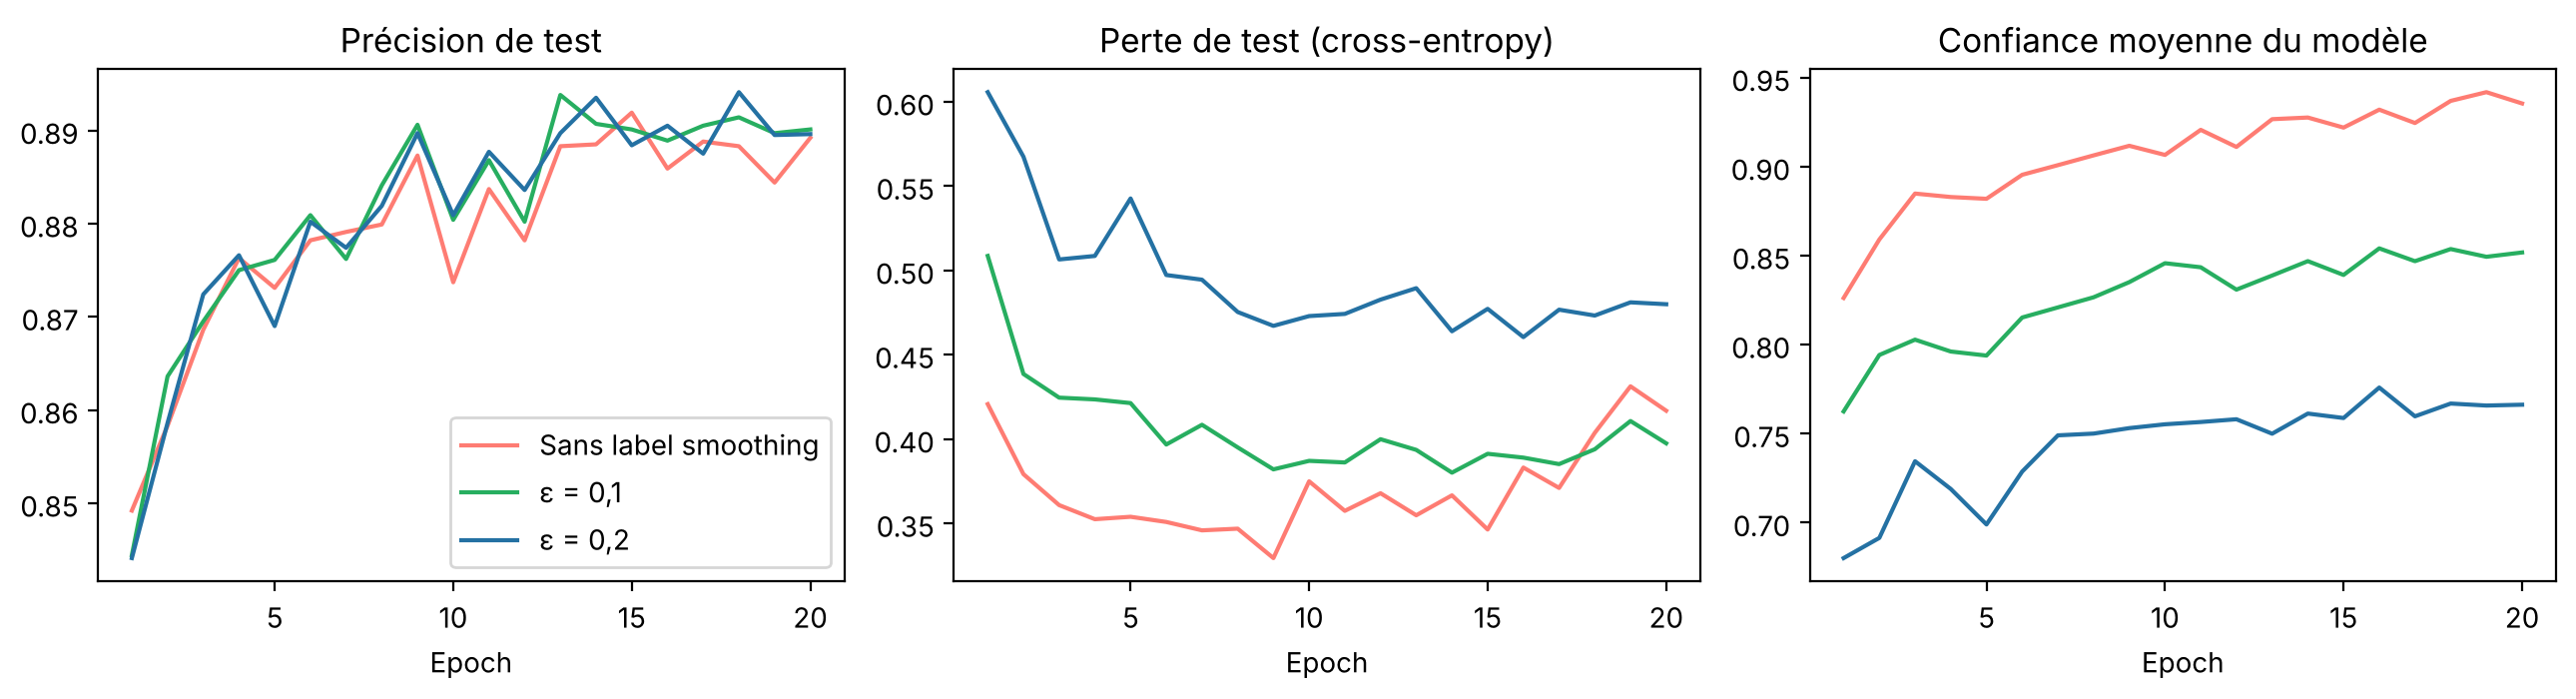

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

for ax, colonne, titre in zip(axes,
                              ["précision", "perte test", "confiance moyenne"],
                              ["Précision de test", "Perte de test (cross-entropy)", "Confiance moyenne du modèle"]):
    ax.plot(hist_sans.index, hist_sans[colonne], label="Sans label smoothing", color="#fe7c73")
    ax.plot(hist_01.index, hist_01[colonne], label="ε = 0,1", color="#27AE60")
    ax.plot(hist_avec.index, hist_avec[colonne], label="ε = 0,2", color="#2471A3")
    ax.set_title(titre)
    ax.set_xlabel("Epoch")

axes[0].legend()
plt.tight_layout()
plt.show()

In [12]:
resume = pd.DataFrame({
    "Sans label smoothing": hist_sans.iloc[-1],
    "ε = 0,1": hist_01.iloc[-1],
    "ε = 0,2": hist_avec.iloc[-1],
}).T
resume["écart confiance - précision"] = resume["confiance moyenne"] - resume["précision"]
resume.round(3)

,précision,perte test,confiance moyenne,écart confiance - précision
Sans label smoothing,0.889,0.417,0.935,0.046
"ε = 0,1",0.890,0.397,0.852,-0.038
"ε = 0,2",0.890,0.480,0.766,-0.123


Comment lire ces résultats (chiffres de cette exécution) :

- **Précision** : identique, environ 89 %, pour les trois modèles. Le label smoothing ne fait pas gagner de points ici : son effet est ailleurs.
- **Confiance moyenne** : sans label smoothing, elle monte à chaque epoch (jusqu'à environ 93 %) alors que la précision stagne à 89 % : le modèle est plus confiant que précis. Le label smoothing **plafonne** cette confiance : environ 85 % avec ε = 0,1 et 77 % avec ε = 0,2.
- **Attention au choix de ε** : avec ε = 0,2, la confiance (77 %) tombe **sous** la précision (89 %) : le modèle devient sous-confiant. Avec ε = 0,1, l'écart est de quelques points, dans le même sens. Le label smoothing ne calibre pas automatiquement : il baisse la confiance, et c'est à toi de régler ε.
- **Perte de test** : sans label smoothing, elle remonte vers la fin de l'entraînement (le modèle devient trop sûr de lui sur ses erreurs). À la fin de l'entraînement, elle est la plus basse avec ε = 0,1. Elle est plus haute avec ε = 0,2, parce que la cross-entropy classique pénalise un modèle volontairement moins confiant.

## 7. Les probabilités de sortie sur une image

On regarde la prédiction du modèle sans label smoothing et du modèle avec ε = 0,2 sur la première image de test :

In [13]:
image, etiquette = test_dataset[0]
print("Vraie classe :", classes[etiquette])

with torch.no_grad():
    p_sans = F.softmax(net_sans.eval()(image.unsqueeze(0).to(device)), dim=1)[0].cpu().numpy()
    p_avec = F.softmax(net_avec.eval()(image.unsqueeze(0).to(device)), dim=1)[0].cpu().numpy()

pd.DataFrame({"Sans label smoothing": p_sans, "Avec label smoothing": p_avec}, index=classes).round(4)

Vraie classe : Botte


,Sans label smoothing,Avec label smoothing
T-shirt,0.0000,0.0176
Pantalon,0.0000,0.0200
Pull,0.0000,0.0201
Robe,0.0000,0.0190
Manteau,0.0000,0.0194
Sandale,0.0000,0.0205
Chemise,0.0000,0.0203
Basket,0.0001,0.0145
Sac,0.0000,0.0214
Botte,0.9999,0.8270


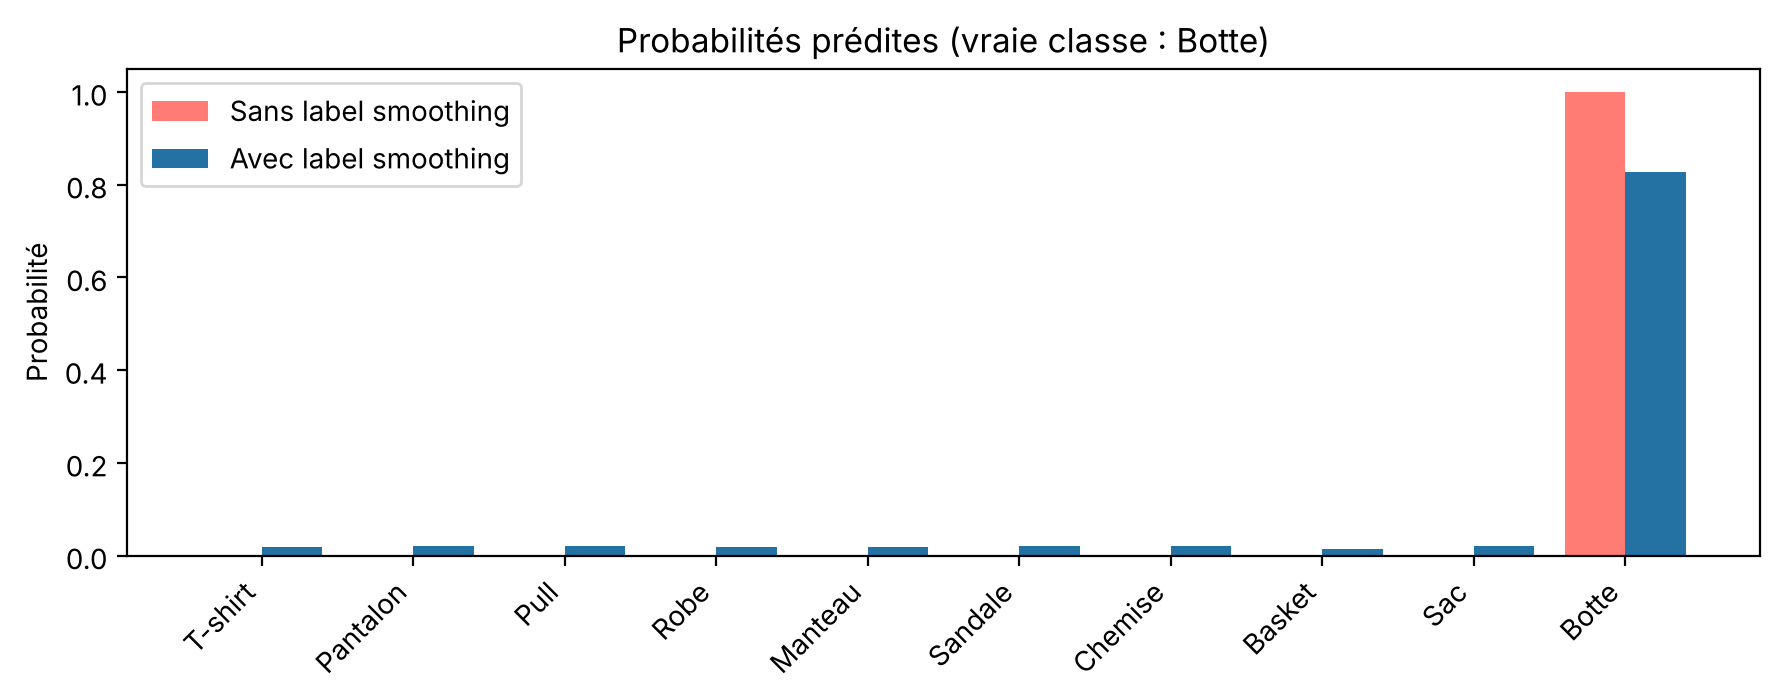

In [14]:
x = np.arange(len(classes))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, p_sans, width=0.4, label="Sans label smoothing", color="#fe7c73")
ax.bar(x + 0.2, p_avec, width=0.4, label="Avec label smoothing", color="#2471A3")
ax.set_xticks(x, classes, rotation=45, ha="right")
ax.set_ylabel("Probabilité")
ax.set_title(f"Probabilités prédites (vraie classe : {classes[etiquette]})")
ax.legend()
plt.tight_layout()
plt.show()

Sans label smoothing, le modèle met presque toute la probabilité sur une seule classe et des valeurs minuscules sur les autres. Avec label smoothing (ε = 0,2), la classe prédite reste la plus probable (environ 83 %, proche de la cible de 0,82), et chacune des autres classes garde environ 2 % : le modèle ne prétend plus être certain.

## 8. Quand l'utiliser ?

- **Utile** pour limiter la sur-confiance d'un modèle (probabilités moins extrêmes), freiner le surapprentissage des erreurs, ou quand certaines étiquettes d'entraînement sont bruitées.
- **Précaution** : le label smoothing baisse la confiance, il ne la calibre pas. Avec un ε trop grand, le modèle devient sous-confiant (c'est le cas ici avec ε = 0,2). Une probabilité de 82 % n'a plus le même sens qu'avant : si tu utilises les probabilités pour autre chose que le classement (seuils de décision, distillation de modèle), vérifie l'effet.
- `ε` est un hyperparamètre : 0,1 est une valeur courante pour commencer. Compare plusieurs valeurs sur un jeu de validation, avec la précision, la perte et l'écart confiance moyenne - précision.

## 9. Ce qu'il faut retenir

- Le label smoothing remplace la cible « 100 % / 0 % » par une cible adoucie : le modèle n'est plus poussé à être infiniment confiant.
- Dans PyTorch : `nn.CrossEntropyLoss(label_smoothing=0.2)`. Avec 10 classes, la bonne classe reçoit 0,82 et chacune des 9 autres 0,02.
- La perte d'entraînement n'est pas comparable à celle d'un modèle sans label smoothing : compare les modèles sur la précision et la perte de test classique.
- L'effet principal n'est pas un gain de précision, mais des probabilités plus calibrées : la confiance du modèle se rapproche de sa précision.
- `ε` est un hyperparamètre : commence par 0,1 et valide sur un jeu de validation.

---

## Pour aller plus loin

- [La vraie origine du terme de régularisation (et pourquoi on le met au carré)](https://www.monshotdata.com/p/terme-regularisation) — d'où vient la régularisation
- [Visualisation de l'impact des paramètres de régularisation](https://www.monshotdata.com/p/visualisation-de-l-impact-des-parametres-de-regularisation) — l'effet de la régularisation en images
- [Ton classifieur te dit-il vraiment ce qu'il ignore ?](https://www.monshotdata.com/p/modeles-discriminatifs-probabilistes-vs-labellisation) — ce que valent vraiment les probabilités d'un classifieur
- [Tous les notebooks des shots](https://github.com/moncoachdata/MonShotData) — le code Python de la newsletter, rangé par thème